# 01. Волны, интерференция и оптический путь

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** вывести уравнение интерферограммы, понять контраст, когерентность и двойной проход.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Что в действительности усредняет камера

Для квазимонохроматического света в одной точке $E_j(t)=A_j\cos(\omega t+\phi_j)$.
Частота оптического поля намного выше частоты кадров. Время экспозиции содержит
огромное число периодов, поэтому камера чувствительна к $\langle E^2\rangle_t$,
а не к мгновенному E. Здесь E — скалярная компонента поля при согласованных поляризациях.

Сначала складываем **поля**, затем возводим в квадрат:
$$\langle(E_1+E_2)^2\rangle=\langle E_1^2\rangle+\langle E_2^2\rangle
+2\langle E_1E_2\rangle.$$
Используем $\langle\cos^2\rangle=1/2$ и
$2\cos\alpha\cos\beta=\cos(\alpha-\beta)+\cos(\alpha+\beta)$.
Быстро осциллирующая сумма фаз усредняется в ноль. Получаем:
$$I=I_1+I_2+2\sqrt{I_1I_2}\cos(\phi_1-\phi_2).$$
Это источник основного уравнения всего курса, а не эмпирическая подгонка.

Численное усреднение / формула: 0.9986504281336561 0.9986504281336714


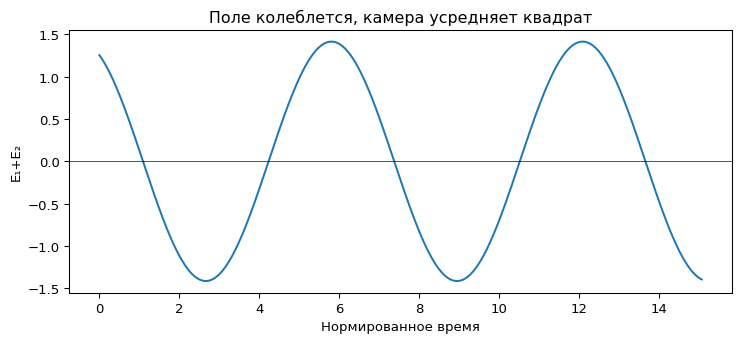

In [2]:
phase_difference = 1.2
amplitude_1, amplitude_2 = 1., .7
t = np.linspace(0, 200*2*np.pi, 100000, endpoint=False)
E1 = amplitude_1*np.cos(t)
E2 = amplitude_2*np.cos(t+phase_difference)
measured = np.mean((E1+E2)**2)
predicted = (amplitude_1**2+amplitude_2**2)/2+amplitude_1*amplitude_2*np.cos(phase_difference)
print("Численное усреднение / формула:",measured,predicted)
assert np.isclose(measured,predicted,atol=1e-10)
plt.plot(t[:1200],(E1+E2)[:1200]); plt.axhline(0,color='k',lw=.5)
plt.xlabel('Нормированное время'); plt.ylabel('E₁+E₂'); plt.title('Поле колеблется, камера усредняет квадрат')
plt.show()

## 2. Комплексная запись того же вывода

Пусть $U_j=A_je^{i\phi_j}$ — комплексные амплитуды. Тогда
$$|U_1+U_2|^2=|U_1|^2+|U_2|^2+U_1U_2^*+U_1^*U_2.$$
Последние два члена дают $2\operatorname{Re}(U_1U_2^*)$.
Фактор 1/2 временного усреднения можно включить в определение интенсивности.

Обозначим $a=I_1+I_2$, $b=2\sqrt{I_1I_2}$, $\varphi=\phi_1-\phi_2$.
Тогда $I=a+b\cos\varphi$. Фон a и амплитуда b в реальной системе зависят от X,Y:
неравномерность пучка, затенение и чувствительность камеры не исчезают из модели.

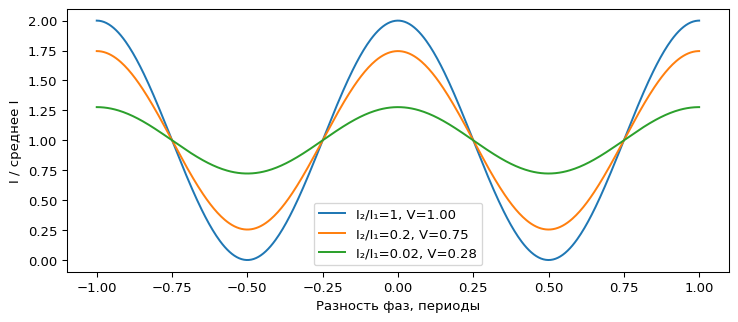

In [3]:
phase = np.linspace(-2*np.pi,2*np.pi,500)
fig,ax=plt.subplots()
for ratio in [1.,.2,.02]:
    i1,i2=1.,ratio
    intensity=i1+i2+2*np.sqrt(i1*i2)*np.cos(phase)
    visibility=2*np.sqrt(i1*i2)/(i1+i2)
    ax.plot(phase/(2*np.pi),intensity/(i1+i2),label=f'I₂/I₁={ratio:g}, V={visibility:.2f}')
ax.set(xlabel='Разность фаз, периоды',ylabel='I / среднее I'); ax.legend(); plt.show()

## 3. Видность, поляризация и когерентность

При постоянных a,b видность $V=(I_{max}-I_{min})/(I_{max}+I_{min})=b/a$.
Для согласованных поляризаций и полной когерентности V максимальна при $I_1=I_2$.
Усиление одного пучка без другого может **ухудшить** видность.

Более общая запись:
$$I=I_1+I_2+2\sqrt{I_1I_2}\operatorname{Re}\{\gamma_{12}e^{i\varphi}\},$$
где комплексная степень когерентности $|\gamma_{12}|\le1$ учитывает взаимную
стабильность полей. Для двух линейных поляризаций дополнительно появляется
скалярное произведение единичных векторов: при ортогональных поляризациях полос нет.

Для гауссова распределения оптических частот с СКО σν:
$|\gamma(\tau)|=\exp[-(2\pi\sigma_\nu\tau)^2/2]$.
Время задержки $\tau=W/c$. Число «длина когерентности» зависит от принятого
критерия ширины; формула для конкретной линии надёжнее неопределённого коэффициента.

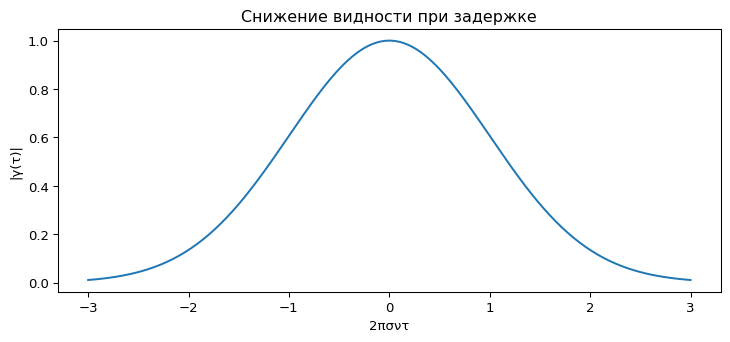

In [4]:
delay = np.linspace(-3,3,300)  # в единицах 1/(2πσν)
coherence = np.exp(-delay**2/2)
plt.plot(delay,coherence)
plt.xlabel('2πσντ'); plt.ylabel('|γ(τ)|'); plt.title('Снижение видности при задержке')
plt.show()

## 4. От оптического пути к поверхности

Оптический путь $L_{opt}=\int n(s)\,ds$; OPD — разность путей рабочего и опорного
пучков. Используем длину волны в вакууме: $\varphi=2\pi W/\lambda_0$.

В простой отражательной геометрии при нормальном падении смещение зеркала на h
меняет путь туда и обратно: $W=2h$. При угле падения θ к нормали для малого смещения
плоской поверхности $W=2h\cos\theta$. Для сложного хода лучей и CGH этого уже
недостаточно: требуется оптическое отображение.

Наклон фронта создаёт несущую: $N(x,y)=f_xx+f_yy+N_{err}(x,y)$.
Полосы — линии равного N. Чаша даёт кольца, большой наклон превращает их в открытые
дуги. Твайман—Грин сравнивает рабочее и опорное плечи; измеряется их разность,
а не только ошибка исследуемой детали.

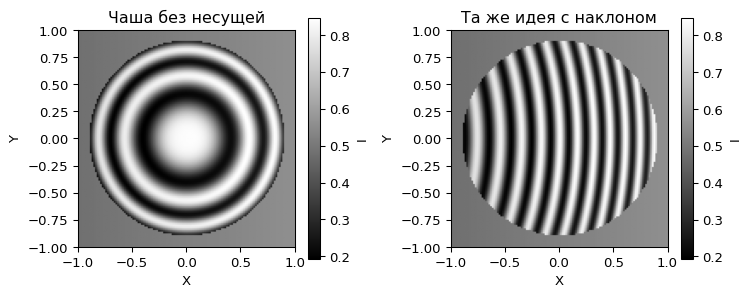

По единственной интенсивности знаки +φ и −φ неразличимы.


In [5]:
scenes = [cl.scene(carrier_x=0,carrier_y=0,bowl=3,astig=0),
          cl.scene(carrier_x=12,carrier_y=0,bowl=1,astig=0)]
cl.show_maps([s['image'] for s in scenes],['Чаша без несущей','Та же идея с наклоном'],cmap='gray',units='I')
s=scenes[1]
assert np.allclose(s['a']+s['b']*np.cos(s['phi']),s['a']+s['b']*np.cos(-s['phi']))
print('По единственной интенсивности знаки +φ и −φ неразличимы.')

## Задания

1. Почему нельзя складывать интенсивности двух когерентных пучков как независимые числа?
2. Найдите V при $I_1/I_2=9$. Как изменится ответ для ортогональных поляризаций?
3. Сколько периодов OPD соответствует высоте 1 μm при λ=10.6 μm и нормальном отражении?
4. Задайте такую добавку к N, которая изменит знак поверхности, но сохранит изображение.

<details><summary>Разбор</summary>

1. Потеряется перекрёстный член. 2. V=0.6; при ортогональных поляризациях V=0.
3. N=2/10.6≈0.18868. 4. Замена всего N на −N сохраняет cos(2πN).
Прибавка целого числа к N также не меняет изображение, но это другая неоднозначность.
</details>

**Чтение:** [двухволновая интерференция, University of Arizona](https://webs.optics.arizona.edu/gsmith/interference.html).
**В проекте:** `WavefrontReconstructionStage.cpp` отвечает за перевод порядков в длину.
Далее: [дискретизация и камера](02_camera_sampling.ipynb).